# Gráficos del Proyecto 1 - HPC 2026: Estimación de π y e con Monte Carlo

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

## Dispersión Cartesiana 2D de Pi (N = 10^6)

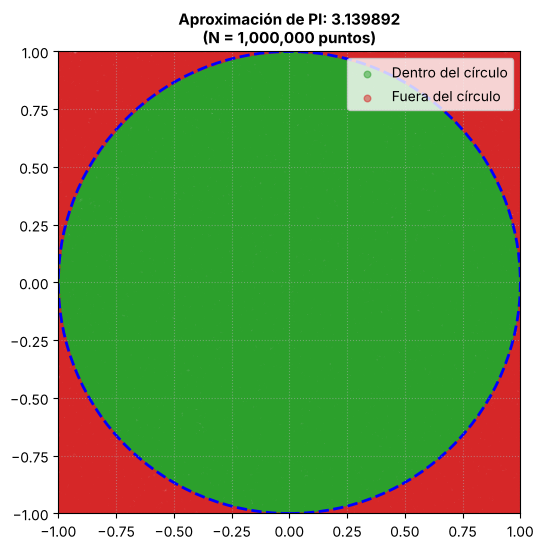

In [ ]:
np.random.seed(42)
N = 1_000_000
x = np.random.uniform(-1.0, 1.0, N)
y = np.random.uniform(-1.0, 1.0, N)
dentro = (x**2 + y**2 <= 1.0)
pi_aprox = 4.0 * np.sum(dentro) / N

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[dentro], y[dentro], color='tab:green', s=0.1, alpha=0.5, rasterized=True, label='Dentro del círculo')
ax.scatter(x[~dentro], y[~dentro], color='tab:red', s=0.1, alpha=0.5, rasterized=True, label='Fuera del círculo')
circulo = plt.Circle((0, 0), 1.0, color='blue', fill=False, linestyle='--', linewidth=2)
ax.add_patch(circulo)

ax.set_xlim(-1.0, 1.0)
ax.set_ylim(-1.0, 1.0)
ax.set_aspect('equal')
plt.title(f"Aproximación de PI: {pi_aprox:.6f}\n(N = {N:,} puntos)", fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper right', markerscale=15)
plt.show()

## Evolución Espacial y Densificación Progresiva de Pi (Matriz 2x3)

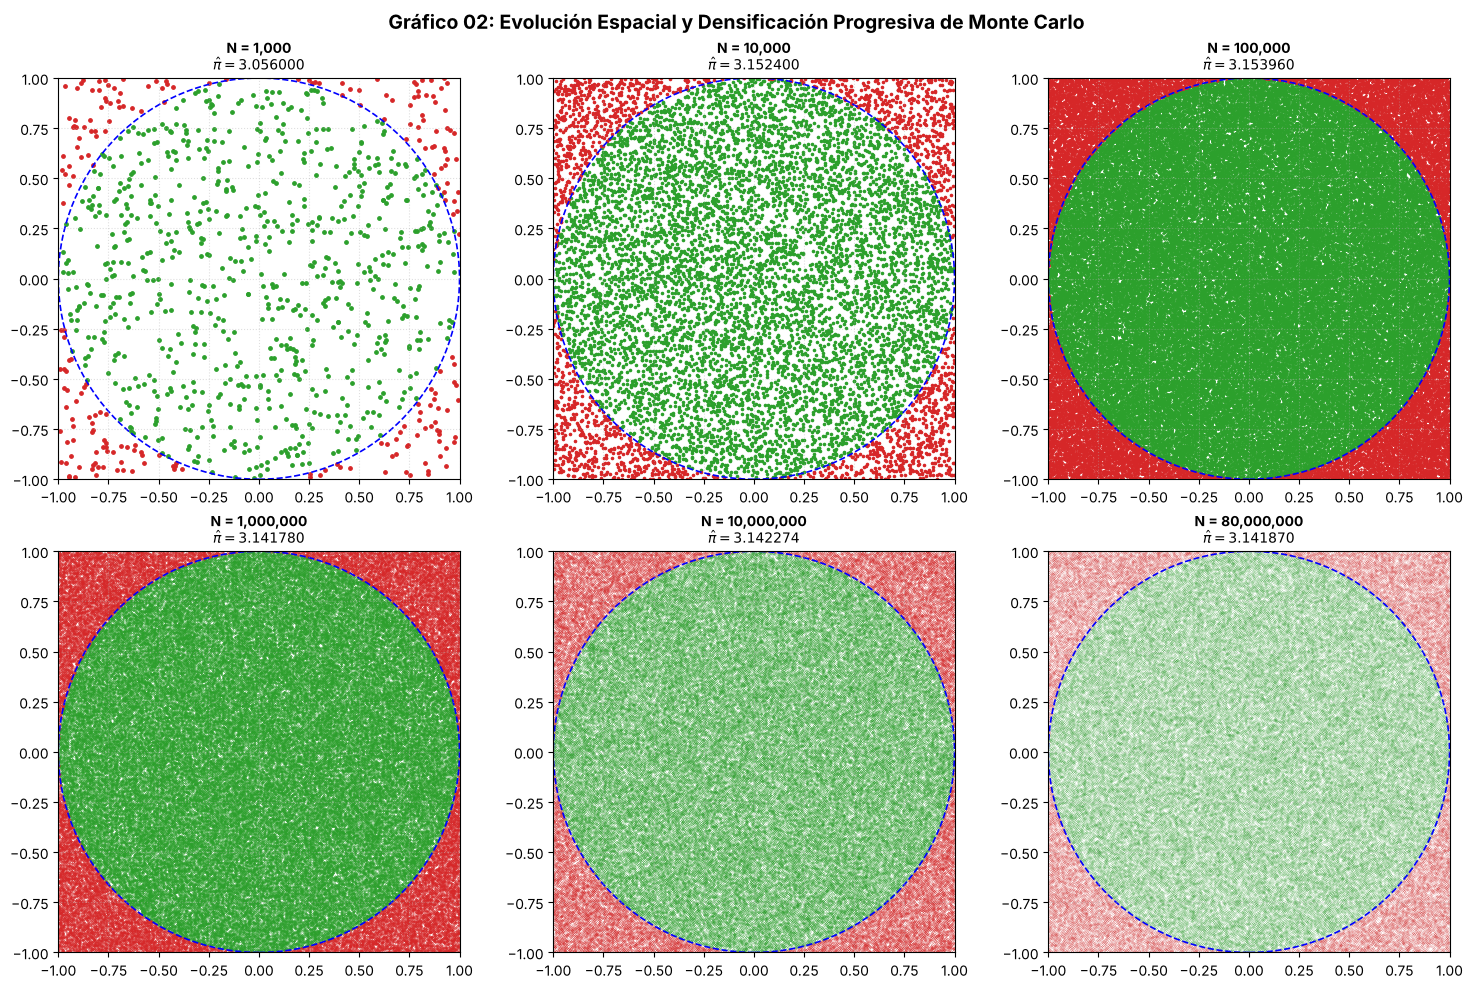

In [ ]:
np.random.seed(42)
N_vals = [10**3, 10**4, 10**5, 10**6, 10**7, 80_000_000]
s_sizes = [6.0, 2.5, 0.8, 0.1, 0.02, 0.005]
pi_estimados = [3.056000, 3.152400, 3.153960, 3.141780, 3.142274, 3.141870]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (N, s, pi_hat) in enumerate(zip(N_vals, s_sizes, pi_estimados)):
    ax = axes[i]
    N_plot = min(N, 150_000)
    x = np.random.uniform(-1.0, 1.0, N_plot)
    y = np.random.uniform(-1.0, 1.0, N_plot)
    dentro = (x**2 + y**2 <= 1.0)

    ax.scatter(x[dentro], y[dentro], color='tab:green', s=s, rasterized=True)
    ax.scatter(x[~dentro], y[~dentro], color='tab:red', s=s, rasterized=True)
    circulo = plt.Circle((0, 0), 1.0, color='blue', fill=False, linestyle='--', linewidth=1.2)
    ax.add_patch(circulo)

    ax.set_xlim(-1.0, 1.0)
    ax.set_ylim(-1.0, 1.0)
    ax.set_aspect('equal')
    ax.set_title(f"N = {N:,}\n$\\hat{{\\pi}} = {pi_hat:.6f}$", fontsize=10, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle("Gráfico 02: Evolución Espacial y Densificación Progresiva de Monte Carlo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Convergencia de Monte Carlo a Pi vs. N

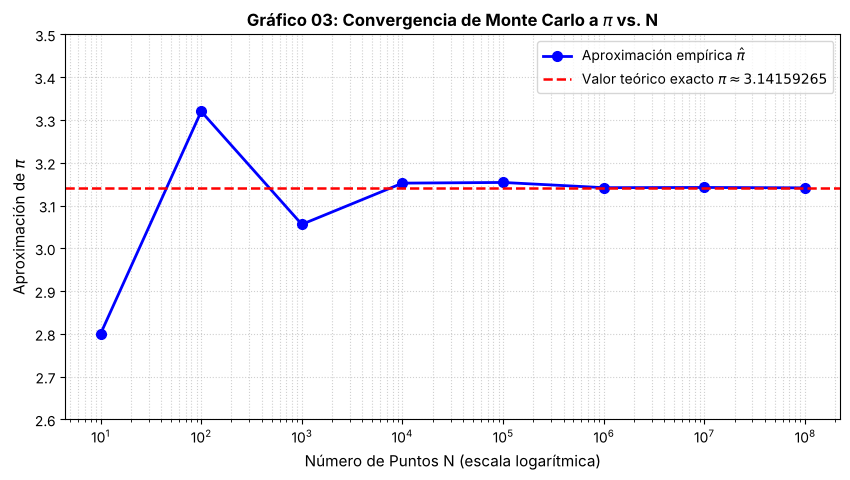

In [ ]:
N_puntos = [10**i for i in range(1, 9)]
pi_aprox = [2.800000, 3.320000, 3.056000, 3.152400, 3.153960, 3.141780, 3.142274, 3.141402]

plt.figure(figsize=(10, 5))
plt.plot(N_puntos, pi_aprox, 'bo-', linewidth=2, markersize=7, label=r'Aproximación empírica $\hat{\pi}$')
plt.axhline(y=np.pi, color='r', linestyle='--', linewidth=1.8, label=r'Valor teórico exacto $\pi \approx 3.14159265$')

plt.xscale('log')
plt.xlabel('Número de Puntos N (escala logarítmica)', fontsize=11)
plt.ylabel(r'Aproximación de $\pi$', fontsize=11)
plt.title(r'Gráfico 03: Convergencia de Monte Carlo a $\pi$ vs. N', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.legend(fontsize=10)
plt.ylim(2.6, 3.5)
plt.show()

## Error Relativo de Pi vs. N por Procesos (P = 2, 4, 6)

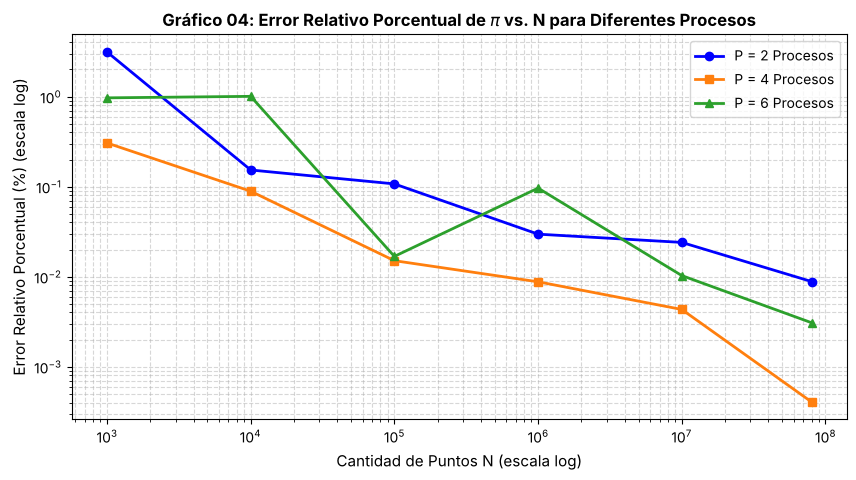

In [ ]:
N_vals = [1e3, 1e4, 1e5, 1e6, 1e7, 8e7]
err_p2 = [3.132403, 0.153023, 0.107186, 0.029646, 0.024009, 0.008828]
err_p4 = [0.305344, 0.088893, 0.015045, 0.008765, 0.004321, 0.000406]
err_p6 = [0.967896, 1.006093, 0.016786, 0.096236, 0.010280, 0.003078]

plt.figure(figsize=(10, 5))
plt.plot(N_vals, err_p2, 'bo-', linewidth=2, label='P = 2 Procesos')
plt.plot(N_vals, err_p4, 's-', color='tab:orange', linewidth=2, label='P = 4 Procesos')
plt.plot(N_vals, err_p6, '^-', color='tab:green', linewidth=2, label='P = 6 Procesos')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Cantidad de Puntos N (escala log)', fontsize=11)
plt.ylabel('Error Relativo Porcentual (%) (escala log)', fontsize=11)
plt.title('Gráfico 04: Error Relativo Porcentual de $\\pi$ vs. N para Diferentes Procesos', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=10)
plt.show()

## Distribución de Extracciones de Euler N* vs. Símplex Teórico

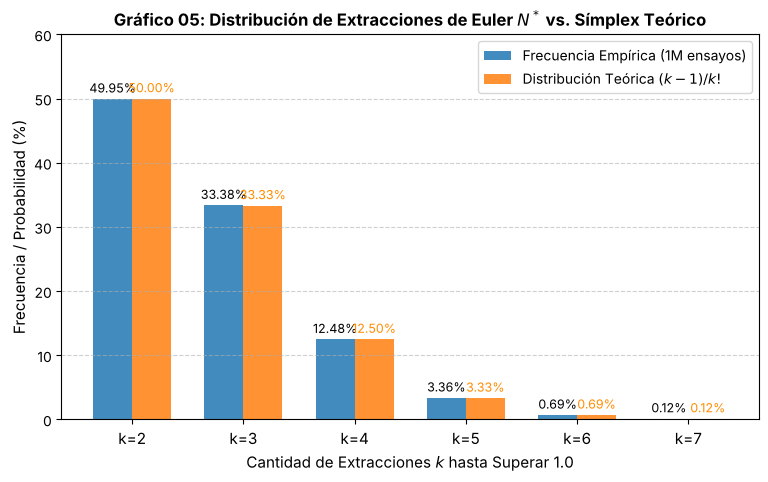

In [ ]:
np.random.seed(42)
n_ensayos = 1_000_000
conteos = []

for _ in range(n_ensayos):
    s = 0.0
    c = 0
    while s <= 1.0:
        s += np.random.uniform(0.0, 1.0)
        c += 1
    conteos.append(c)

k_valores = np.arange(2, 8)
frec_empiricas = [np.mean(np.array(conteos) == k) * 100.0 for k in k_valores]
frec_teoricas = [((k - 1) / math.factorial(k)) * 100.0 for k in k_valores]

plt.figure(figsize=(9, 5))
x = np.arange(len(k_valores))
width = 0.35

plt.bar(x - width/2, frec_empiricas, width, label='Frecuencia Empírica (1M ensayos)', color='tab:blue', alpha=0.85)
plt.bar(x + width/2, frec_teoricas, width, label=r'Distribución Teórica $(k-1)/k!$', color='tab:orange', alpha=0.85)

for i in range(len(k_valores)):
    plt.text(x[i] - width/2, frec_empiricas[i] + 1.0, f"{frec_empiricas[i]:.2f}%", ha='center', fontsize=9)
    plt.text(x[i] + width/2, frec_teoricas[i] + 1.0, f"{frec_teoricas[i]:.2f}%", ha='center', fontsize=9, color='darkorange')

plt.xticks(x, [f"k={k}" for k in k_valores], fontsize=11)
plt.xlabel('Cantidad de Extracciones $k$ hasta Superar 1.0', fontsize=11)
plt.ylabel('Frecuencia / Probabilidad (%)', fontsize=11)
plt.title('Gráfico 05: Distribución de Extracciones de Euler $N^*$ vs. Símplex Teórico', fontsize=12, fontweight='bold')
plt.ylim(0, 60)
plt.legend(fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

## Convergencia de Monte Carlo a la Constante de Euler vs. N

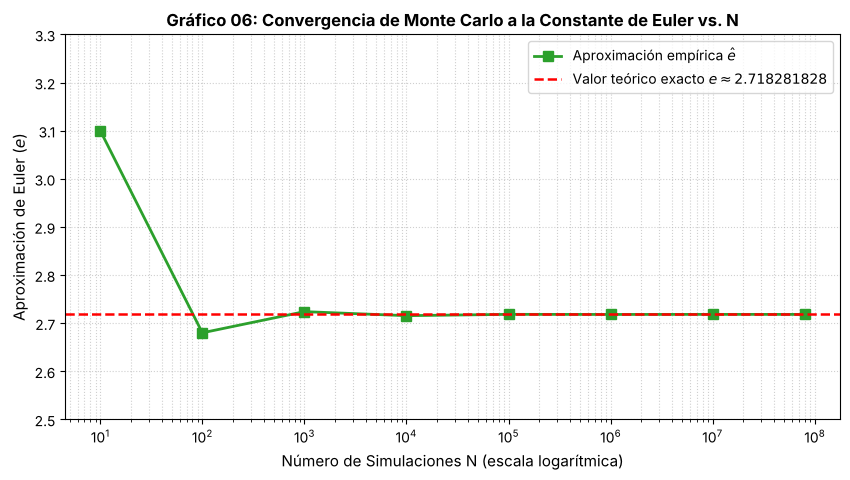

In [ ]:
N_puntos = [10, 100, 1000, 10000, 100000, 1000000, 10000000, 80000000]
euler_aprox = [3.100000, 2.680000, 2.724000, 2.715600, 2.718360, 2.718134, 2.718302, 2.718231]
e_real = np.e

plt.figure(figsize=(10, 5))
plt.plot(N_puntos, euler_aprox, 's-', color='tab:green', linewidth=2, markersize=7, label=r'Aproximación empírica $\hat{e}$')
plt.axhline(y=e_real, color='r', linestyle='--', linewidth=1.8, label=r'Valor teórico exacto $e \approx 2.718281828$')

plt.xscale('log')
plt.xlabel('Número de Simulaciones N (escala logarítmica)', fontsize=11)
plt.ylabel(r'Aproximación de Euler ($e$)', fontsize=11)
plt.title(r'Gráfico 06: Convergencia de Monte Carlo a la Constante de Euler vs. N', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls=":", alpha=0.6)
plt.legend(fontsize=10)
plt.ylim(2.5, 3.3)
plt.show()

## Error Relativo Comparativo: Pi vs. Euler en Log-Log

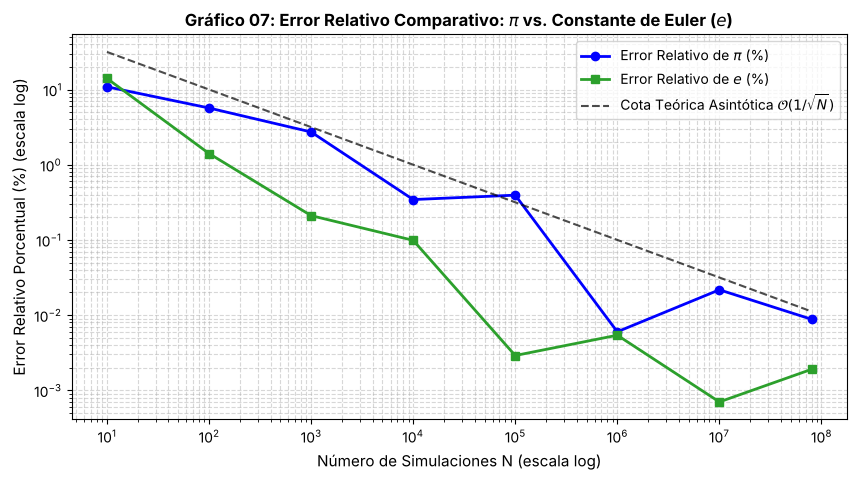

In [ ]:
N_vals = np.array([10, 100, 1000, 10000, 100000, 1000000, 10000000, 80000000])
err_pi = [10.8738, 5.6789, 2.7245, 0.3440, 0.3937, 0.0060, 0.0217, 0.0088]
err_euler = [14.0425, 1.4083, 0.2104, 0.0987, 0.0029, 0.0054, 0.0007, 0.0019]
cota_teorica = 100.0 / np.sqrt(N_vals)

plt.figure(figsize=(10, 5))
plt.plot(N_vals, err_pi, 'bo-', linewidth=2, markersize=6, label=r'Error Relativo de $\pi$ (%)')
plt.plot(N_vals, err_euler, 's-', color='tab:green', linewidth=2, markersize=6, label=r'Error Relativo de $e$ (%)')
plt.plot(N_vals, cota_teorica, 'k--', linewidth=1.5, alpha=0.7, label=r'Cota Teórica Asintótica $\mathcal{O}(1/\sqrt{N})$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Número de Simulaciones N (escala log)', fontsize=11)
plt.ylabel('Error Relativo Porcentual (%) (escala log)', fontsize=11)
plt.title(r'Gráfico 07: Error Relativo Comparativo: $\pi$ vs. Constante de Euler ($e$)', fontsize=12, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=10)
plt.show()

## Tiempo de Ejecución y SpeedUp vs. Procesos (PC, N = 10^7)

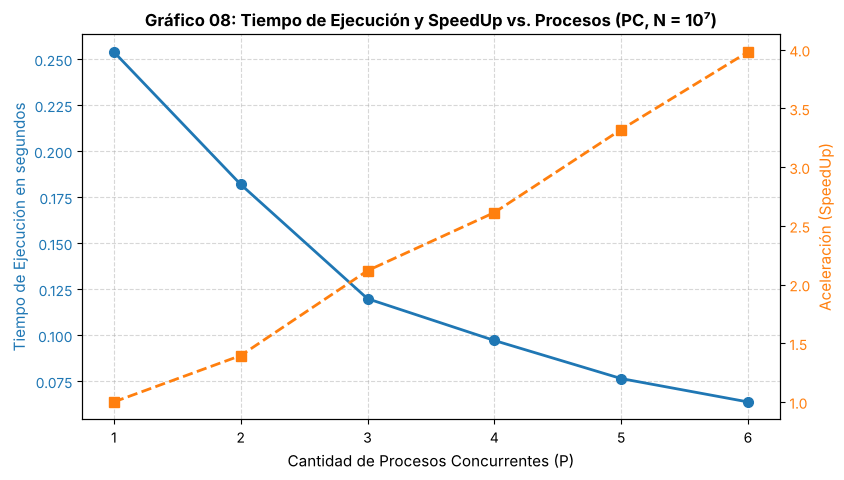

In [ ]:
procesos = [1, 2, 3, 4, 5, 6]
tiempos = [0.2540, 0.1820, 0.1199, 0.0972, 0.0765, 0.0638]
speedup = [1.000, 1.395, 2.118, 2.613, 3.320, 3.981]

fig, ax1 = plt.subplots(figsize=(9, 5))

color_tiempo = 'tab:blue'
ax1.set_xlabel('Cantidad de Procesos Concurrentes (P)', fontsize=11)
ax1.set_ylabel('Tiempo de Ejecución en segundos', color=color_tiempo, fontsize=11)
ax1.plot(procesos, tiempos, 'o-', color=color_tiempo, linewidth=2, markersize=7, label='Tiempo de Ejecución (s)')
ax1.tick_params(axis='y', labelcolor=color_tiempo)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color_sp = 'tab:orange'
ax2.set_ylabel('Aceleración (SpeedUp)', color=color_sp, fontsize=11)
ax2.plot(procesos, speedup, 's--', color=color_sp, linewidth=2, markersize=7, label='SpeedUp Experimental')
ax2.tick_params(axis='y', labelcolor=color_sp)

plt.title('Gráfico 08: Tiempo de Ejecución y SpeedUp vs. Procesos (PC, N = 10⁷)', fontsize=12, fontweight='bold')
plt.show()

## Eficiencia vs. Procesos (PC, N = 10^7)

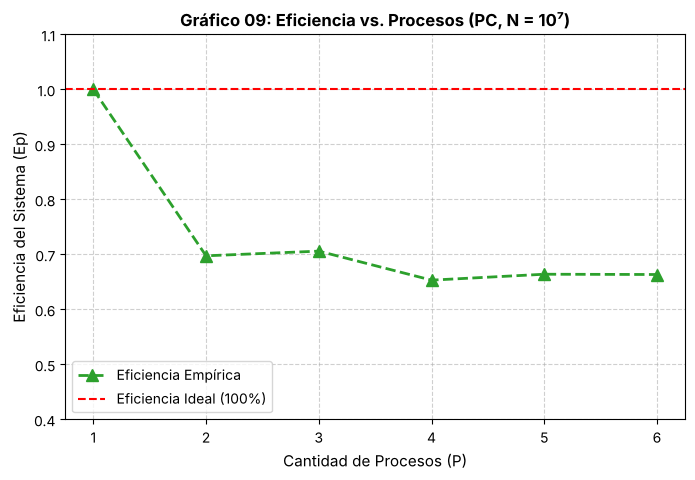

In [ ]:
procesos = [1, 2, 3, 4, 5, 6]
speedup = [1.000, 1.395, 2.118, 2.613, 3.320, 3.981]
eficiencia = [s / p for s, p in zip(speedup, procesos)]

plt.figure(figsize=(8, 5))
plt.plot(procesos, eficiencia, '^--', color='tab:green', linewidth=2, markersize=8, label='Eficiencia Empírica')
plt.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, label='Eficiencia Ideal (100%)')

plt.xlabel('Cantidad de Procesos (P)', fontsize=11)
plt.ylabel('Eficiencia del Sistema (Ep)', fontsize=11)
plt.title('Gráfico 09: Eficiencia vs. Procesos (PC, N = 10⁷)', fontsize=12, fontweight='bold')
plt.ylim(0.4, 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Tiempo de Ejecución y SpeedUp en Clúster FaMAF (N = 10^11)

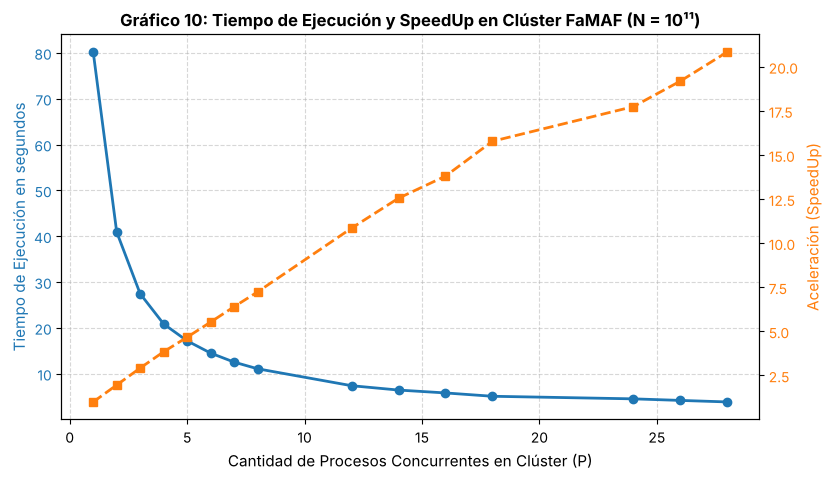

In [ ]:
procesos = [1, 2, 3, 4, 5, 6, 7, 8, 12, 14, 16, 18, 24, 26, 28]
tiempos = [80.2071, 40.9269, 27.4455, 20.8579, 17.1720, 14.5046, 12.5327,
           11.0790, 7.3894, 6.4384, 5.8100, 5.0828, 4.5196, 4.1795, 3.8473]
speedup = [1.000, 1.959, 2.922, 3.845, 4.671, 5.529, 6.399, 7.239,
           10.854, 12.553, 13.805, 15.780, 17.746, 19.191, 20.847]

fig, ax1 = plt.subplots(figsize=(9, 5))

color_tiempo = 'tab:blue'
ax1.set_xlabel('Cantidad de Procesos Concurrentes en Clúster (P)', fontsize=11)
ax1.set_ylabel('Tiempo de Ejecución en segundos', color=color_tiempo, fontsize=11)
ax1.plot(procesos, tiempos, 'o-', color=color_tiempo, linewidth=2, markersize=6, label='Tiempo de Ejecución (s)')
ax1.tick_params(axis='y', labelcolor=color_tiempo)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color_sp = 'tab:orange'
ax2.set_ylabel('Aceleración (SpeedUp)', color=color_sp, fontsize=11)
ax2.plot(procesos, speedup, 's--', color=color_sp, linewidth=2, markersize=6, label='SpeedUp Experimental')
ax2.tick_params(axis='y', labelcolor=color_sp)

plt.title('Gráfico 10: Tiempo de Ejecución y SpeedUp en Clúster FaMAF (N = 10¹¹)', fontsize=12, fontweight='bold')
plt.show()

## Eficiencia vs. Procesos en Clúster FaMAF (N = 10^11)

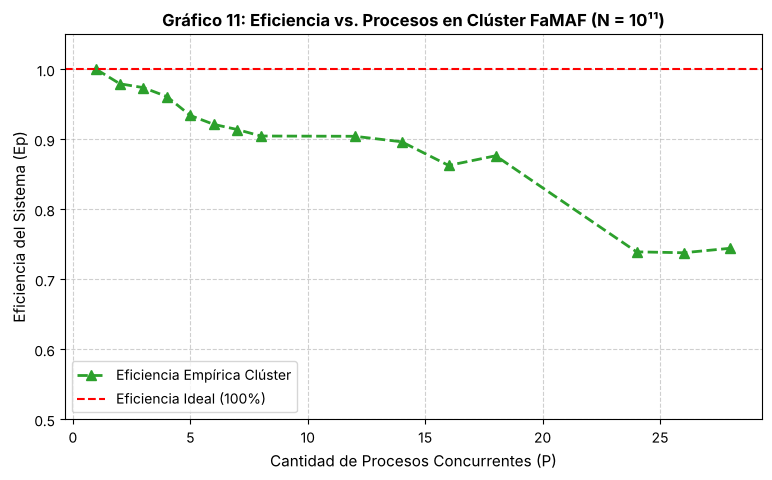

In [ ]:
procesos = [1, 2, 3, 4, 5, 6, 7, 8, 12, 14, 16, 18, 24, 26, 28]
speedup = [1.000, 1.959, 2.922, 3.845, 4.671, 5.529, 6.399, 7.239,
           10.854, 12.553, 13.805, 15.780, 17.746, 19.191, 20.847]
eficiencia = [s / p for s, p in zip(speedup, procesos)]

plt.figure(figsize=(9, 5))
plt.plot(procesos, eficiencia, '^--', color='tab:green', linewidth=2, markersize=7, label='Eficiencia Empírica Clúster')
plt.axhline(y=1.0, color='red', linestyle='--', linewidth=1.5, label='Eficiencia Ideal (100%)')

plt.xlabel('Cantidad de Procesos Concurrentes (P)', fontsize=11)
plt.ylabel('Eficiencia del Sistema (Ep)', fontsize=11)
plt.title('Gráfico 11: Eficiencia vs. Procesos en Clúster FaMAF (N = 10¹¹)', fontsize=12, fontweight='bold')
plt.ylim(0.5, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()